# MT9 - Background Sound Classification and Voice Activity Detection

**Amirkabir University of Technology**  
**Department of Computer Engineering**  
**Course:** Digital Speech Processing  
**Instructor:** Dr. Mohammad Khalooei  
**Student:** Anas Raad Radih Alaasam  
**Student ID:** 404131083  
**Email:** anas.r.r.alaasam@gmail.com

## Introduction

In this mini-task, I used the VOiCES-subset recordings to study background sound classification and voice activity detection under different acoustic conditions.

I classified the background condition of each complete recording as no distractor, babble, music, or television. I did not estimate the onset or offset of individual background events in this recording-level experiment.

I also implemented two speech activity detection approaches, classical energy-based VAD and pretrained Silero VAD, and compared their predicted speech intervals.

I worked with the smaller VOiCES-subset dataset to keep the experiments manageable in Google Colab. I organized the notebook around dataset inspection, acoustic feature extraction, model evaluation, VAD analysis, and discussion of the observed results.


## Environment and Dependencies

I checked the available Python libraries and storage before downloading the dataset.

In [1]:
import sys
import shutil
import subprocess
import importlib.util
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Python version:", sys.version.split()[0])

libraries = [
    "torch",
    "torchaudio",
    "librosa",
    "soundfile",
    "sklearn",
    "scipy"
]

for library in libraries:
    available = importlib.util.find_spec(library) is not None
    print(f"{library}: {'Available' if available else 'Missing'}")

disk = shutil.disk_usage("/content")

print("\nAvailable disk space (GB):",
      round(disk.free / (1024 ** 3), 2))

Python version: 3.13.18
torch: Available
torchaudio: Available
librosa: Available
soundfile: Available
sklearn: Available
scipy: Available

Available disk space (GB): 107.62


## Dataset Download

I cloned the instructor-recommended VOiCES subset into the Colab workspace.

In [2]:
from pathlib import Path
import subprocess

repo_url = "https://github.com/Lab41/VOiCES-subset.git"

dataset_path = Path("/content/VOiCES-subset")

if not dataset_path.exists():

    subprocess.run(
        [
            "git",
            "clone",
            "--depth",
            "1",
            repo_url,
            str(dataset_path)
        ],
        check=True
    )

else:
    print("Dataset repository already exists.")

print("\nRepository directory:", dataset_path)
print("Repository exists:", dataset_path.exists())


Repository directory: /content/VOiCES-subset
Repository exists: True


In [3]:
from pathlib import Path

dataset_path = Path("/content/VOiCES-subset")

if not dataset_path.is_dir():
    raise FileNotFoundError(
        "VOiCES-subset directory was not found."
    )

print("Dataset Repository Contents\n")

for item in sorted(dataset_path.iterdir()):

    if item.is_file():
        size_mb = item.stat().st_size / (1024 ** 2)

        print(
            f"FILE: {item.name} "
            f"({size_mb:.2f} MB)"
        )

    elif item.is_dir():
        print(f"DIR:  {item.name}")

tar_files = sorted(dataset_path.glob("*.tar"))

csv_files = sorted(dataset_path.glob("*.csv"))

print("\nNumber of TAR files:", len(tar_files))
print("Number of CSV files:", len(csv_files))

print("\nTAR archives:")
for file in tar_files:
    print(file.name)

print("\nCSV files:")
for file in csv_files:
    print(file.name)

Dataset Repository Contents

DIR:  .git
FILE: Feature Extraction.ipynb (0.04 MB)
FILE: Lab41-SRI-VOiCES-speaker-gender-dataset_SUBSET.csv (0.00 MB)
FILE: Lab41-SRI-VOiCES_ref_SUBSET.csv (0.44 MB)
FILE: Loading VOiCES data.ipynb (1.17 MB)
FILE: README.md (0.00 MB)
FILE: VOiCES_90_1.tar (45.41 MB)
FILE: VOiCES_90_2.tar (45.89 MB)
FILE: VOiCES_90_3.tar (45.93 MB)
FILE: VOiCES_90_4.tar (45.06 MB)
FILE: VOiCES_90_5.tar (44.90 MB)
FILE: VOiCES_90_6.tar (43.97 MB)
FILE: VOiCES_90_7.tar (44.73 MB)
FILE: VOiCES_90_8.tar (46.15 MB)
FILE: VOiCES_90deg_features.csv (1.04 MB)
DIR:  VOiCES_workshop

Number of TAR files: 8
Number of CSV files: 3

TAR archives:
VOiCES_90_1.tar
VOiCES_90_2.tar
VOiCES_90_3.tar
VOiCES_90_4.tar
VOiCES_90_5.tar
VOiCES_90_6.tar
VOiCES_90_7.tar
VOiCES_90_8.tar

CSV files:
Lab41-SRI-VOiCES-speaker-gender-dataset_SUBSET.csv
Lab41-SRI-VOiCES_ref_SUBSET.csv
VOiCES_90deg_features.csv


## Dataset Structure and Label Inspection

I downloaded the VOiCES-subset repository suggested by the instructor.

The repository contains eight TAR archives with audio recordings, three CSV files, and supporting notebooks.

Before starting the experiments, I inspected the metadata and archive contents to understand the dataset structure and identify the available audio labels.

This step helps me select appropriate recordings for background classification and voice activity detection.

In [4]:
import pandas as pd
from pathlib import Path

dataset_path = Path("/content/VOiCES-subset")

csv_files = sorted(dataset_path.glob("*.csv"))

for csv_file in csv_files:

    print("\n" + "=" * 65)
    print("File:", csv_file.name)

    df = pd.read_csv(csv_file)

    print("Shape:", df.shape)

    print("\nColumns:")
    print(df.columns.tolist())

    print("\nFirst 3 rows:")
    print(df.head(3).to_string(index=False))


File: Lab41-SRI-VOiCES-speaker-gender-dataset_SUBSET.csv
Shape: (104, 3)

Columns:
['Speaker', 'Gender', 'DataSet']

First 3 rows:
 Speaker Gender         DataSet
    5126      M train-clean-360
    3549      F train-clean-360
    4331      F train-clean-360

File: Lab41-SRI-VOiCES_ref_SUBSET.csv
Shape: (1500, 2)

Columns:
['fileName', 'trnscrpt']

First 3 rows:
                                                           fileName                                                                                                                                                                                                                                                                             trnscrpt
Lab41-SRI-VOiCES-rm1-musi-sp5126-ch036956-sg0011-mc07-stu-beh-dg090                                                                     a wink from mister lord must have been intended to convey a great deal because owing to the defect in his eyes it required no little exertion and even th

## Audio Archive and Label Distribution

I inspected the WAV members of the TAR archives without extracting them.

In [5]:
import tarfile
import pandas as pd
from pathlib import Path
from collections import Counter

dataset_path = Path("/content/VOiCES-subset")

tar_files = sorted(dataset_path.glob("VOiCES_90_*.tar"))

audio_files = []
archive_summary = []

for tar_path in tar_files:

    with tarfile.open(tar_path, "r:*") as archive:

        members = [
            member.name
            for member in archive.getmembers()
            if member.isfile()
            and member.name.lower().endswith(".wav")
        ]

    audio_files.extend(members)

    archive_summary.append({
        "Archive": tar_path.name,
        "WAV_Count": len(members)
    })

summary_df = pd.DataFrame(archive_summary)

print("Audio Archive Summary:")
print(summary_df.to_string(index=False))

print("\nTotal WAV files:", len(audio_files))

print("\nFirst 10 WAV filenames:")
for name in audio_files[:10]:
    print(name)

noise_codes = Counter()

for name in audio_files:
    filename = Path(name).stem
    parts = filename.split("-")

    if len(parts) >= 5:
        noise_codes[parts[4]] += 1

print("\nBackground distribution:")
for noise, count in sorted(noise_codes.items()):
    print(f"{noise}: {count}")

print("\nUnique filenames:", len(set(audio_files)))

Audio Archive Summary:
        Archive  WAV_Count
VOiCES_90_1.tar        114
VOiCES_90_2.tar        113
VOiCES_90_3.tar        113
VOiCES_90_4.tar        113
VOiCES_90_5.tar        113
VOiCES_90_6.tar        113
VOiCES_90_7.tar        115
VOiCES_90_8.tar        115

Total WAV files: 909

First 10 WAV filenames:
Users/mbarrios/Documents/VOICES/IQT_Github_repo/90deg_50-50/part_1/Lab41-SRI-VOiCES-rm2-babb-sp1472-ch285314-sg0013-mc03-stu-mid-dg090.wav
Users/mbarrios/Documents/VOICES/IQT_Github_repo/90deg_50-50/part_1/Lab41-SRI-VOiCES-rm1-tele-sp2294-ch161714-sg0019-mc01-stu-clo-dg090.wav
Users/mbarrios/Documents/VOICES/IQT_Github_repo/90deg_50-50/part_1/Lab41-SRI-VOiCES-rm1-none-sp3972-ch005791-sg0005-mc03-stu-mid-dg090.wav
Users/mbarrios/Documents/VOICES/IQT_Github_repo/90deg_50-50/part_1/Lab41-SRI-VOiCES-rm2-tele-sp5386-ch004145-sg0031-mc07-stu-beh-dg090.wav
Users/mbarrios/Documents/VOICES/IQT_Github_repo/90deg_50-50/part_1/Lab41-SRI-VOiCES-rm1-musi-sp2532-ch157475-sg0012-mc03-stu-mid-dg

## Audio Inspection and Visualization

I inspected the VOiCES-subset archives and identified four background conditions: none, babble, music, and television.

I found 909 WAV-named archive members, including one non-audio AppleDouble entry, which I excluded before analysis.

I selected one recording from each background class to examine the audio properties and visualize the signals.

I used waveform and spectrogram representations to compare the acoustic characteristics of the different background conditions.

In [6]:
import tarfile
import io
import numpy as np
import pandas as pd
import soundfile as sf
import matplotlib.pyplot as plt
from pathlib import Path

dataset_path = Path("/content/VOiCES-subset")

tar_files = sorted(dataset_path.glob("VOiCES_90_*.tar"))

background_labels = {
    "none": "No Distractor",
    "babb": "Babble",
    "musi": "Music",
    "tele": "Television"
}

audio_examples = {}
audio_information = []

for tar_path in tar_files:

    if len(audio_examples) == len(background_labels):
        break

    with tarfile.open(tar_path, "r:*") as archive:

        for member in archive:

            if not member.isfile():
                continue

            if not member.name.lower().endswith(".wav"):
                continue

            filename = Path(member.name).stem
            parts = filename.split("-")

            if len(parts) < 5:
                continue

            background = parts[4]

            if background not in background_labels:
                continue

            if background in audio_examples:
                continue

            extracted_file = archive.extractfile(member)

            if extracted_file is None:
                continue

            audio_bytes = extracted_file.read()

            signal, sr = sf.read(
                io.BytesIO(audio_bytes),
                dtype="float32"
            )

            if signal.ndim == 2:
                signal = np.mean(signal, axis=1)

            duration = len(signal) / sr

            audio_examples[background] = {
                "signal": signal,
                "sample_rate": sr,
                "filename": Path(member.name).name
            }

            audio_information.append({
                "Background": background_labels[background],
                "Sample_Rate": sr,
                "Duration_s": duration,
                "Channels_After_Loading": 1,
                "Samples": len(signal)
            })

print("Audio Inspection Results:\n")

audio_info_df = pd.DataFrame(audio_information)

print(audio_info_df.to_string(index=False))

print("\nBackground classes loaded:",
      len(audio_examples))

assert set(audio_examples) == set(background_labels)

print("All four background classes loaded successfully.")

Audio Inspection Results:

   Background  Sample_Rate  Duration_s  Channels_After_Loading  Samples
       Babble        16000      16.005                       1   256080
   Television        16000      16.960                       1   271360
No Distractor        16000      16.485                       1   263760
        Music        16000      15.670                       1   250720

Background classes loaded: 4
All four background classes loaded successfully.



Background: Babble
Filename: Lab41-SRI-VOiCES-rm2-babb-sp1472-ch285314-sg0013-mc03-stu-mid-dg090.wav


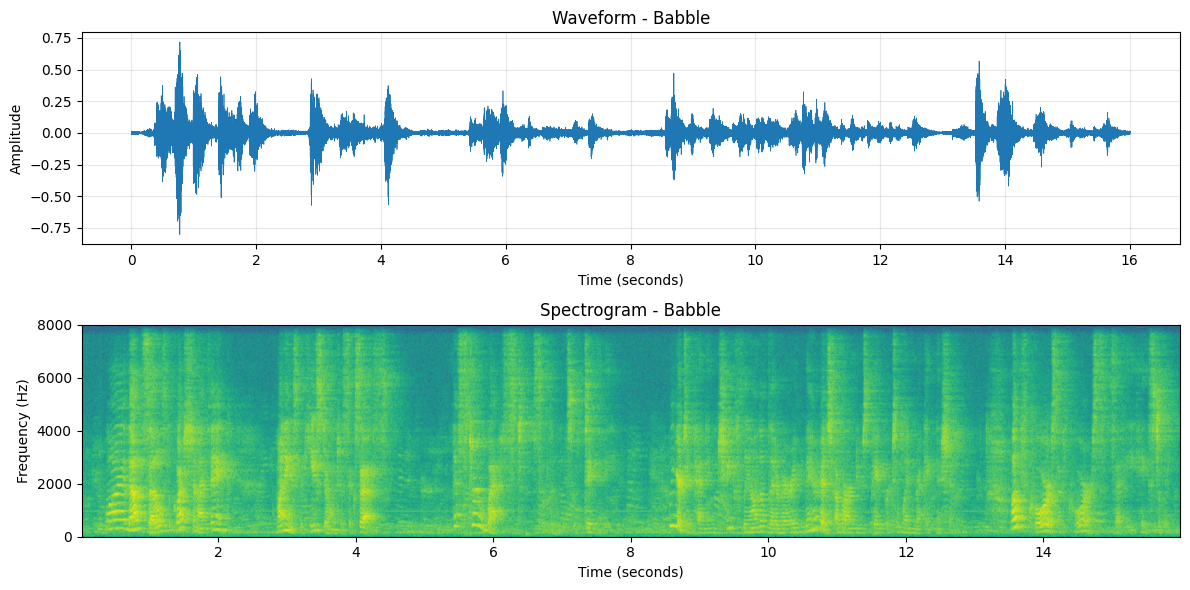


Background: Television
Filename: Lab41-SRI-VOiCES-rm1-tele-sp2294-ch161714-sg0019-mc01-stu-clo-dg090.wav


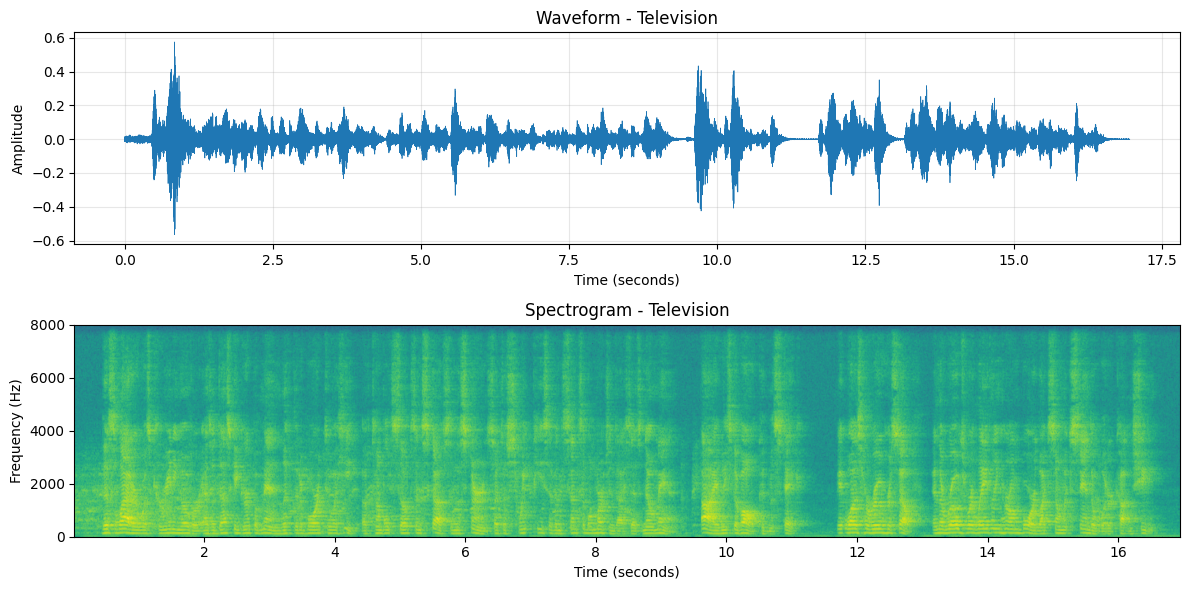


Background: No Distractor
Filename: Lab41-SRI-VOiCES-rm1-none-sp3972-ch005791-sg0005-mc03-stu-mid-dg090.wav


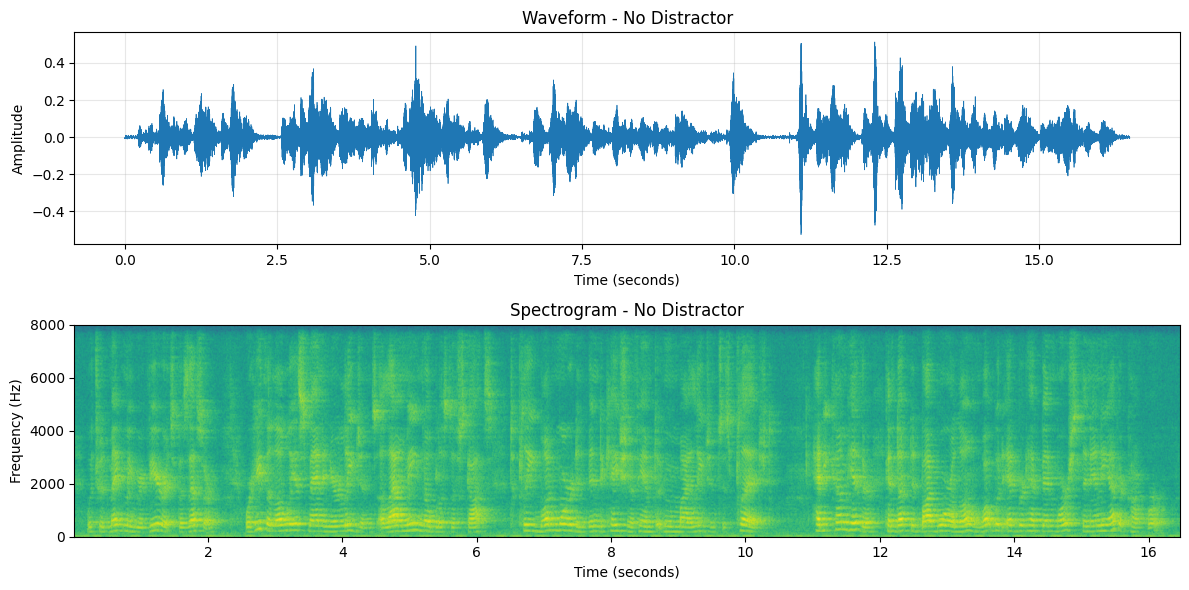


Background: Music
Filename: Lab41-SRI-VOiCES-rm1-musi-sp2532-ch157475-sg0012-mc03-stu-mid-dg090.wav


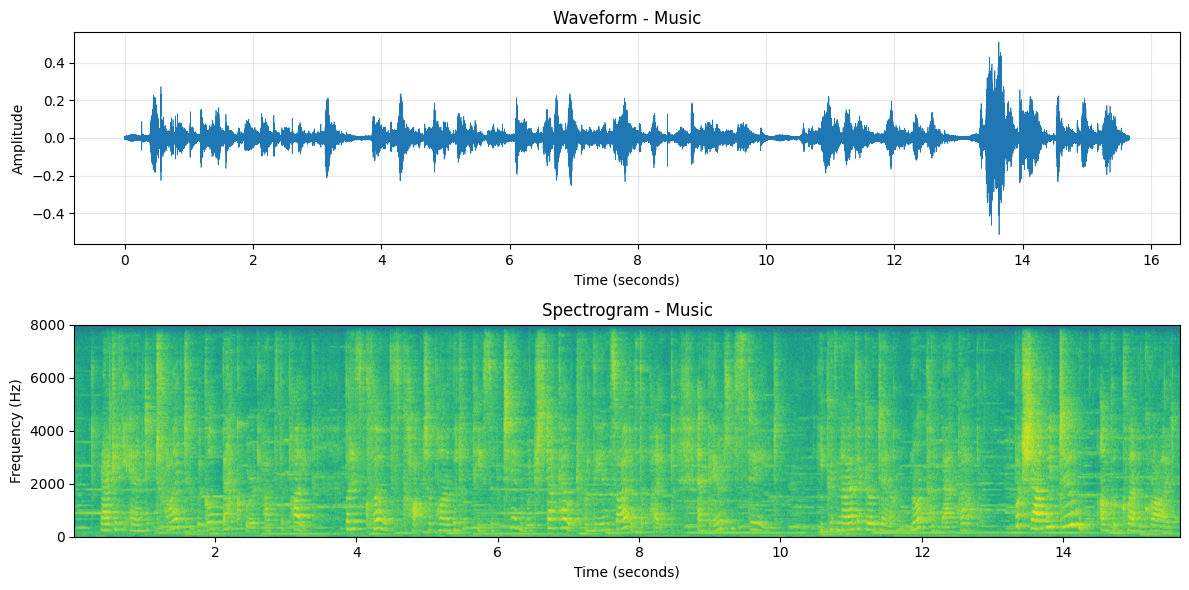

In [7]:
import numpy as np
import matplotlib.pyplot as plt

for background, data in audio_examples.items():

    signal = data["signal"]
    sr = data["sample_rate"]

    time_axis = np.arange(len(signal)) / sr

    print("\nBackground:", background_labels[background])
    print("Filename:", data["filename"])

    fig, axes = plt.subplots(2, 1, figsize=(12, 6))

    axes[0].plot(
        time_axis,
        signal,
        linewidth=0.5
    )

    axes[0].set_title(
        f"Waveform - {background_labels[background]}"
    )
    axes[0].set_xlabel("Time (seconds)")
    axes[0].set_ylabel("Amplitude")
    axes[0].grid(alpha=0.3)

    axes[1].specgram(
        signal,
        NFFT=512,
        Fs=sr,
        noverlap=384,
        cmap="viridis"
    )

    axes[1].set_title(
        f"Spectrogram - {background_labels[background]}"
    )
    axes[1].set_xlabel("Time (seconds)")
    axes[1].set_ylabel("Frequency (Hz)")
    axes[1].set_ylim(0, sr / 2)

    plt.tight_layout()
    plt.show()

## Dataset Extraction and Validation

I extracted audio recordings and excluded one non-audio AppleDouble entry that could not be decoded as WAV.

In [8]:
import tarfile
import pandas as pd
import soundfile as sf
from pathlib import Path

dataset_path = Path("/content/VOiCES-subset")
output_path = Path("/content/MT9_audio")
output_path.mkdir(parents=True, exist_ok=True)

records = []
skipped_files = []

valid_labels = {"none", "babb", "musi", "tele"}

for tar_path in sorted(dataset_path.glob("VOiCES_90_*.tar")):

    with tarfile.open(tar_path, "r:*") as archive:

        for member in archive:

            if not member.isfile() or not member.name.lower().endswith(".wav"):
                continue

            filename = Path(member.name).name
            parts = Path(filename).stem.split("-")

            if len(parts) != 12:
                skipped_files.append((filename, "Invalid filename structure"))
                continue

            label = parts[4]
            speaker = parts[5]

            if label not in valid_labels:
                skipped_files.append((filename, "Unknown background label"))
                continue

            destination = output_path / filename

            if not destination.exists():

                source = archive.extractfile(member)

                if source is None:
                    skipped_files.append((filename, "Unable to extract audio"))
                    continue

                with open(destination, "wb") as f:
                    while True:
                        chunk = source.read(1024 * 1024)
                        if not chunk:
                            break
                        f.write(chunk)

            try:
                info = sf.info(str(destination))

                records.append({
                    "filename": filename,
                    "path": str(destination),
                    "label": label,
                    "speaker": speaker,
                    "sample_rate": info.samplerate,
                    "duration": info.duration,
                    "channels": info.channels
                })

            except Exception as e:
                skipped_files.append((filename, str(e)))
                destination.unlink(missing_ok=True)

dataset_df = pd.DataFrame(records)

if dataset_df.empty:
    raise RuntimeError("No valid audio files were prepared.")

print("Dataset Preparation Results")
print("Total valid audio files:", len(dataset_df))
print("Skipped files:", len(skipped_files))

print("\nBackground Distribution:")
print(dataset_df["label"].value_counts().sort_index())

print("\nSample Rates:")
print(dataset_df["sample_rate"].value_counts())

print("\nAudio Channels:")
print(dataset_df["channels"].value_counts())

print("\nDuration Statistics:")
print(dataset_df["duration"].describe())

print("\nUnique Speakers:")
print(dataset_df["speaker"].nunique())

if skipped_files:
    print("\nFirst skipped files:")
    for filename, reason in skipped_files[:10]:
        print(filename, "-", reason)

dataset_df.to_csv(
    "/content/MT9_dataset_metadata.csv",
    index=False
)

print("\nMetadata saved successfully.")

Dataset Preparation Results
Total valid audio files: 908
Skipped files: 1

Background Distribution:
label
babb    228
musi    231
none    227
tele    222
Name: count, dtype: int64

Sample Rates:
sample_rate
16000    908
Name: count, dtype: int64

Audio Channels:
channels
1    908
Name: count, dtype: int64

Duration Statistics:
count    908.000000
mean      15.560374
std        2.055387
min        2.660000
25%       15.565000
50%       15.985000
75%       16.370000
max       19.100000
Name: duration, dtype: float64

Unique Speakers:
104

First skipped files:
._Lab41-SRI-VOiCES-rm2-tele-sp8118-ch268287-sg0020-mc05-stu-far-dg090.wav - Error opening '/content/MT9_audio/._Lab41-SRI-VOiCES-rm2-tele-sp8118-ch268287-sg0020-mc05-stu-far-dg090.wav': Format not recognised.

Metadata saved successfully.


## Speaker-Independent Train/Test Split

I grouped recordings by speaker to prevent speaker overlap between the training and test sets.

In [9]:
from sklearn.model_selection import GroupShuffleSplit

X = dataset_df["path"]
y = dataset_df["label"]
groups = dataset_df["speaker"]

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.25,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups)
)

train_df = dataset_df.iloc[train_idx].copy()
test_df = dataset_df.iloc[test_idx].copy()

train_speakers = set(train_df["speaker"])
test_speakers = set(test_df["speaker"])

overlap = train_speakers.intersection(test_speakers)

print("Train/Test Split Results")

print("\nTraining recordings:", len(train_df))
print("Testing recordings:", len(test_df))

print("\nTraining speakers:", len(train_speakers))
print("Testing speakers:", len(test_speakers))

print("\nOverlapping speakers:", len(overlap))

print("\nTraining class distribution:")
print(train_df["label"].value_counts().sort_index())

print("\nTesting class distribution:")
print(test_df["label"].value_counts().sort_index())

assert len(overlap) == 0
assert len(train_df) + len(test_df) == len(dataset_df)
assert set(train_idx).isdisjoint(set(test_idx))
assert set(train_df["label"]) == set(test_df["label"])

print("\nSpeaker-independent split verified successfully.")

Train/Test Split Results

Training recordings: 666
Testing recordings: 242

Training speakers: 78
Testing speakers: 26

Overlapping speakers: 0

Training class distribution:
label
babb    165
musi    172
none    162
tele    167
Name: count, dtype: int64

Testing class distribution:
label
babb    63
musi    59
none    65
tele    55
Name: count, dtype: int64

Speaker-independent split verified successfully.


## Acoustic Feature Extraction: Whole Recordings

I extracted 30 summary features per recording from 13 MFCCs, RMS energy and zero-crossing rate.

In [10]:
import numpy as np
import pandas as pd
import librosa
from pathlib import Path

feature_path = Path("/content/MT9_audio_features.csv")

def extract_audio_features(audio_path):

    signal, sr = librosa.load(
        audio_path,
        sr=None,
        mono=True
    )

    if len(signal) == 0:
        raise ValueError("Empty audio signal")

    mfcc = librosa.feature.mfcc(
        y=signal,
        sr=sr,
        n_mfcc=13,
        n_fft=512,
        hop_length=160
    )

    rms = librosa.feature.rms(
        y=signal,
        frame_length=512,
        hop_length=160
    )

    zcr = librosa.feature.zero_crossing_rate(
        y=signal,
        frame_length=512,
        hop_length=160
    )

    features = []

    features.extend(np.mean(mfcc, axis=1))
    features.extend(np.std(mfcc, axis=1))

    features.extend([
        np.mean(rms),
        np.std(rms),
        np.mean(zcr),
        np.std(zcr)
    ])

    return np.asarray(features, dtype=np.float64)


feature_names = (
    [f"mfcc_mean_{i}" for i in range(1, 14)]
    + [f"mfcc_std_{i}" for i in range(1, 14)]
    + ["rms_mean", "rms_std", "zcr_mean", "zcr_std"]
)

feature_rows = []
errors = []

for index, row in enumerate(dataset_df.itertuples(index=False), start=1):

    try:
        features = extract_audio_features(row.path)

        if len(features) != len(feature_names):
            raise ValueError("Unexpected feature dimension")

        if not np.all(np.isfinite(features)):
            raise ValueError("Non-finite feature values")

        result = {
            "filename": row.filename,
            "label": row.label,
            "speaker": row.speaker
        }

        result.update(dict(zip(feature_names, features)))

        feature_rows.append(result)

    except Exception as e:
        errors.append((row.filename, str(e)))

    if index % 100 == 0:
        print(f"Processed {index}/{len(dataset_df)} recordings")


features_df = pd.DataFrame(feature_rows)

print("\nFeature Extraction Results")
print("Total recordings:", len(dataset_df))
print("Successfully processed:", len(features_df))
print("Failed recordings:", len(errors))
print("Number of audio features:", len(feature_names))

if not features_df.empty:
    print("Feature matrix shape:",
          features_df[feature_names].shape)

    print("NaN values:",
          features_df[feature_names].isna().sum().sum())

    print("Infinite values:",
          np.isinf(features_df[feature_names].to_numpy()).sum())

if errors:
    print("\nFirst errors:")
    for filename, error in errors[:10]:
        print(filename, error)

if len(features_df) == len(dataset_df) and not errors:
    features_df.to_csv(feature_path, index=False)
    print("\nFeatures saved successfully.")
else:
    print("\nFeature extraction incomplete. Results not saved.")

Processed 100/908 recordings
Processed 200/908 recordings
Processed 300/908 recordings
Processed 400/908 recordings
Processed 500/908 recordings
Processed 600/908 recordings
Processed 700/908 recordings
Processed 800/908 recordings
Processed 900/908 recordings

Feature Extraction Results
Total recordings: 908
Successfully processed: 908
Failed recordings: 0
Number of audio features: 30
Feature matrix shape: (908, 30)
NaN values: 0
Infinite values: 0

Features saved successfully.


## Background Classification: Baseline SVM

I trained a standardized RBF SVM on whole-recording features and evaluated it on held-out speakers.

In [11]:
import numpy as np
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)

labels = ["none", "babb", "musi", "tele"]

assert features_df["filename"].is_unique
assert set(features_df["filename"]) == set(dataset_df["filename"])

feature_index = features_df.set_index("filename")

train_data = feature_index.loc[train_df["filename"]]
test_data = feature_index.loc[test_df["filename"]]

X_train = train_data[feature_names].to_numpy()
X_test = test_data[feature_names].to_numpy()

y_train = train_data["label"].to_numpy()
y_test = test_data["label"].to_numpy()

assert len(X_train) == 666
assert len(X_test) == 242

assert np.isfinite(X_train).all()
assert np.isfinite(X_test).all()

assert set(train_data["speaker"]).isdisjoint(
    set(test_data["speaker"])
)

svm_model = make_pipeline(
    StandardScaler(),
    SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale",
        random_state=42
    )
)

svm_model.fit(X_train, y_train)

y_pred = svm_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

precision, recall, f1, _ = precision_recall_fscore_support(
    y_test,
    y_pred,
    labels=labels,
    average="macro",
    zero_division=0
)

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=labels
)

print("SVM Background Classification Results")

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nAccuracy:", round(accuracy, 4))
print("Macro Precision:", round(precision, 4))
print("Macro Recall:", round(recall, 4))
print("Macro F1:", round(f1, 4))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=labels,
        zero_division=0
    )
)

print("\nConfusion Matrix:")
print(cm)

print("\nSanity Checks:")
print("Confusion matrix total:", cm.sum())
print("Test samples:", len(y_test))

assert cm.sum() == len(y_test)

print("Evaluation completed successfully.")

SVM Background Classification Results

Training samples: 666
Testing samples: 242

Accuracy: 0.6942
Macro Precision: 0.6932
Macro Recall: 0.6905
Macro F1: 0.6901

Classification Report:
              precision    recall  f1-score   support

        none       0.71      0.65      0.68        65
        babb       0.81      0.87      0.84        63
        musi       0.74      0.66      0.70        59
        tele       0.52      0.58      0.55        55

    accuracy                           0.69       242
   macro avg       0.69      0.69      0.69       242
weighted avg       0.70      0.69      0.69       242


Confusion Matrix:
[[42  1  6 16]
 [ 1 55  3  4]
 [ 8  2 39 10]
 [ 8 10  5 32]]

Sanity Checks:
Confusion matrix total: 242
Test samples: 242
Evaluation completed successfully.


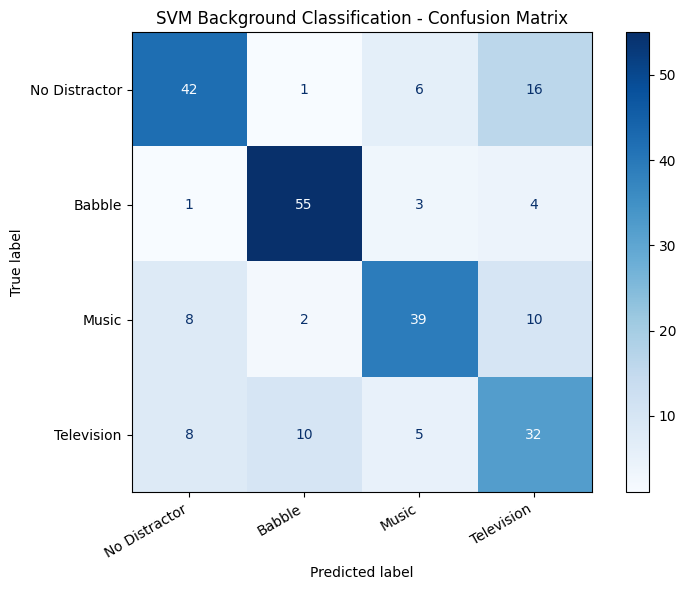

Figure saved: /content/MT9_figures/svm_confusion_matrix.png
Figure exists: True


In [12]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
from pathlib import Path

figures_path = Path("/content/MT9_figures")
figures_path.mkdir(parents=True, exist_ok=True)

display_labels = [
    "No Distractor",
    "Babble",
    "Music",
    "Television"
]

fig, ax = plt.subplots(figsize=(8, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=display_labels
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=True
)

ax.set_title(
    "SVM Background Classification - Confusion Matrix"
)

plt.xticks(rotation=30, ha="right")
plt.tight_layout()

figure_file = figures_path / "svm_confusion_matrix.png"

plt.savefig(
    figure_file,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved:", figure_file)
print("Figure exists:", figure_file.exists())

## Voice Activity Detection: Silero VAD

I applied a pretrained Silero VAD model to speech recordings and visualized predicted speech intervals.

/usr/local/lib/python3.13/dist-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


Silero VAD Results
Background: babb
Filename: Lab41-SRI-VOiCES-rm2-babb-sp1472-ch285314-sg0013-mc03-stu-mid-dg090.wav
Sample Rate: 16000
Duration: 16.005 seconds
Detected Speech Segments: 6

Speech Intervals:
Segment 1: 0.300s - 2.300s
Segment 2: 2.800s - 4.600s
Segment 3: 5.400s - 6.500s
Segment 4: 6.700s - 7.700s
Segment 5: 8.500s - 13.000s
Segment 6: 13.200s - 16.000s


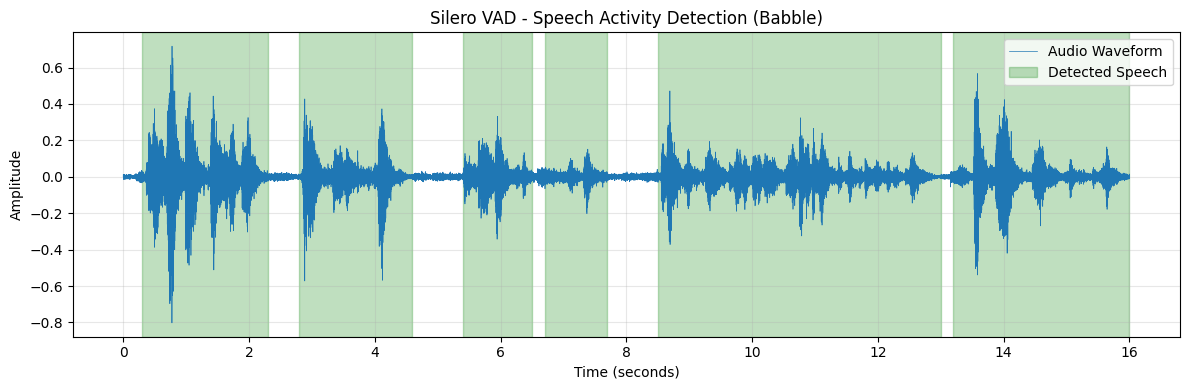

In [13]:
import sys
import subprocess
import importlib.util
import numpy as np
import soundfile as sf
import torch
import matplotlib.pyplot as plt

if importlib.util.find_spec("silero_vad") is None:
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", "silero-vad"],
        check=True
    )

from silero_vad import load_silero_vad, get_speech_timestamps

torch.set_num_threads(1)

vad_model = load_silero_vad()

sample = dataset_df[dataset_df["label"] == "babb"].iloc[0]

signal, sr = sf.read(sample["path"], dtype="float32")

if signal.ndim == 2:
    signal = signal.mean(axis=1)

assert sr == 16000
assert len(signal) > 0

audio_tensor = torch.from_numpy(signal)

speech_segments = get_speech_timestamps(
    audio_tensor,
    vad_model,
    sampling_rate=sr,
    return_seconds=True
)

print("Silero VAD Results")
print("Background:", sample["label"])
print("Filename:", sample["filename"])
print("Sample Rate:", sr)
print("Duration:", round(len(signal) / sr, 3), "seconds")
print("Detected Speech Segments:", len(speech_segments))

print("\nSpeech Intervals:")

for i, segment in enumerate(speech_segments, start=1):
    print(
        f"Segment {i}: "
        f"{segment['start']:.3f}s - "
        f"{segment['end']:.3f}s"
    )

time_axis = np.arange(len(signal)) / sr

fig, ax = plt.subplots(figsize=(12, 4))

ax.plot(
    time_axis,
    signal,
    linewidth=0.5,
    label="Audio Waveform"
)

for i, segment in enumerate(speech_segments):
    ax.axvspan(
        segment["start"],
        segment["end"],
        color="green",
        alpha=0.25,
        label="Detected Speech" if i == 0 else None
    )

ax.set_title("Silero VAD - Speech Activity Detection (Babble)")
ax.set_xlabel("Time (seconds)")
ax.set_ylabel("Amplitude")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

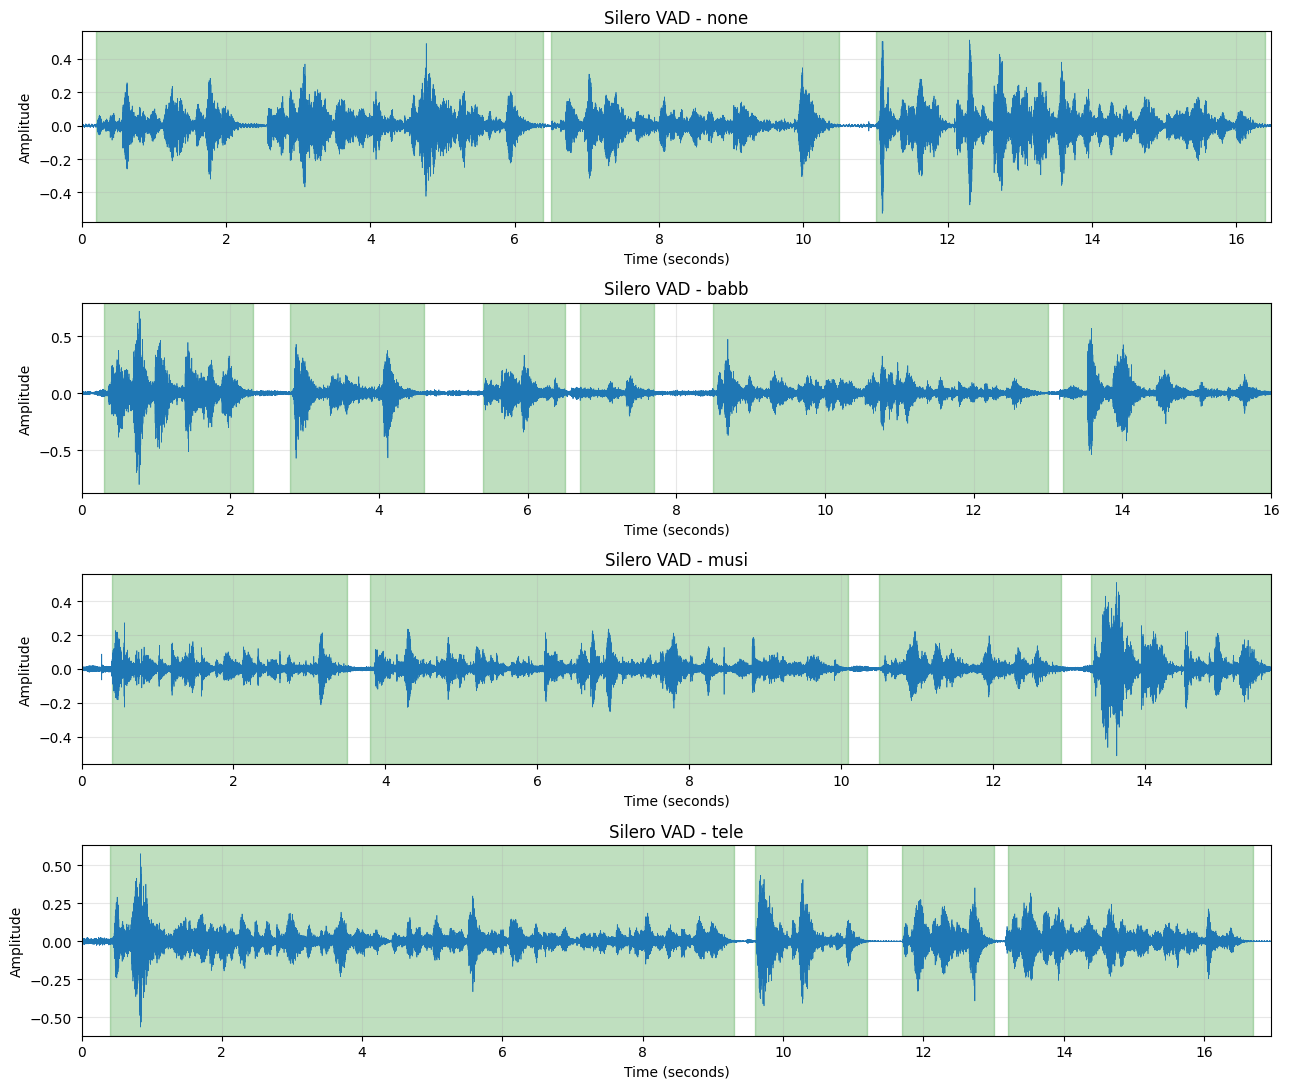


Silero VAD Background Comparison
Background  Duration_s  Speech_Segments  Detected_Speech_s  Speech_Ratio
      none      16.485                3              15.60        0.9463
      babb      16.005                6              13.20        0.8247
      musi      15.670                4              14.17        0.9043
      tele      16.960                4              15.30        0.9021

Figure saved: /content/MT9_figures/silero_vad_backgrounds.png


In [14]:
import numpy as np
import pandas as pd
import soundfile as sf
import torch
import matplotlib.pyplot as plt

from pathlib import Path
from silero_vad import get_speech_timestamps

backgrounds = ["none", "babb", "musi", "tele"]

results = []

fig, axes = plt.subplots(
    4, 1,
    figsize=(13, 11)
)

for ax, background in zip(axes, backgrounds):

    sample = dataset_df[
        dataset_df["label"] == background
    ].iloc[0]

    signal, sr = sf.read(
        sample["path"],
        dtype="float32"
    )

    if signal.ndim == 2:
        signal = signal.mean(axis=1)

    assert sr == 16000

    speech_segments = get_speech_timestamps(
        torch.from_numpy(signal),
        vad_model,
        sampling_rate=sr,
        return_seconds=True
    )

    duration = len(signal) / sr

    speech_duration = sum(
        segment["end"] - segment["start"]
        for segment in speech_segments
    )

    speech_ratio = speech_duration / duration

    results.append({
        "Background": background,
        "Duration_s": round(duration, 3),
        "Speech_Segments": len(speech_segments),
        "Detected_Speech_s": round(speech_duration, 3),
        "Speech_Ratio": round(speech_ratio, 4)
    })

    time_axis = np.arange(len(signal)) / sr

    ax.plot(
        time_axis,
        signal,
        linewidth=0.5
    )

    for segment in speech_segments:
        ax.axvspan(
            segment["start"],
            segment["end"],
            color="green",
            alpha=0.25
        )

    ax.set_title(f"Silero VAD - {background}")
    ax.set_xlabel("Time (seconds)")
    ax.set_ylabel("Amplitude")
    ax.set_xlim(0, duration)
    ax.grid(alpha=0.3)

plt.tight_layout()

figures_path = Path("/content/MT9_figures")
figures_path.mkdir(parents=True, exist_ok=True)

figure_path = figures_path / "silero_vad_backgrounds.png"

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

vad_results_df = pd.DataFrame(results)

print("\nSilero VAD Background Comparison")
print(vad_results_df.to_string(index=False))

print("\nFigure saved:", figure_path)

## Saving Initial Results

I exported the initial SVM and VAD results as CSV files.

In [15]:
from pathlib import Path
import numpy as np

results_path = Path("/content/MT9_results")
results_path.mkdir(parents=True, exist_ok=True)

assert len(vad_results_df) == 4
assert set(vad_results_df["Background"]) == {
    "none", "babb", "musi", "tele"
}

assert (
    vad_results_df["Detected_Speech_s"]
    <= vad_results_df["Duration_s"]
).all()

assert vad_results_df["Speech_Ratio"].between(0, 1).all()

calculated_ratios = (
    vad_results_df["Detected_Speech_s"]
    / vad_results_df["Duration_s"]
)

assert np.allclose(
    calculated_ratios,
    vad_results_df["Speech_Ratio"],
    atol=0.0001
)

output_file = results_path / "vad_background_comparison.csv"

vad_results_df.to_csv(output_file, index=False)

print("VAD Results Verification")
print("Background classes:", len(vad_results_df))
print("All speech durations valid: True")
print("All speech ratios valid: True")
print("Saved file:", output_file)
print("File exists:", output_file.exists())

print("\nFinal VAD Results:")
print(vad_results_df.to_string(index=False))

VAD Results Verification
Background classes: 4
All speech durations valid: True
All speech ratios valid: True
Saved file: /content/MT9_results/vad_background_comparison.csv
File exists: True

Final VAD Results:
Background  Duration_s  Speech_Segments  Detected_Speech_s  Speech_Ratio
      none      16.485                3              15.60        0.9463
      babb      16.005                6              13.20        0.8247
      musi      15.670                4              14.17        0.9043
      tele      16.960                4              15.30        0.9021


In [16]:
import pandas as pd
import numpy as np
from pathlib import Path
from sklearn.metrics import classification_report

results_path = Path("/content/MT9_results")
results_path.mkdir(parents=True, exist_ok=True)

assert len(y_test) == 242
assert len(y_pred) == 242
assert cm.shape == (4, 4)
assert cm.sum() == len(y_test)
assert np.trace(cm) == 168

metrics_df = pd.DataFrame({
    "Model": ["SVM"],
    "Accuracy": [accuracy],
    "Macro_Precision": [precision],
    "Macro_Recall": [recall],
    "Macro_F1": [f1],
    "Training_Samples": [len(y_train)],
    "Testing_Samples": [len(y_test)]
})

metrics_file = results_path / "svm_classification_metrics.csv"
metrics_df.to_csv(metrics_file, index=False)

cm_df = pd.DataFrame(
    cm,
    index=labels,
    columns=labels
)

cm_file = results_path / "svm_confusion_matrix.csv"
cm_df.to_csv(cm_file, index_label="True_Label")

report_df = pd.DataFrame(
    classification_report(
        y_test,
        y_pred,
        labels=labels,
        output_dict=True,
        zero_division=0
    )
).transpose()

report_file = results_path / "svm_classification_report.csv"
report_df.to_csv(report_file, index_label="Class")

print("Background Classification Results Verification")

print("\nModel: SVM")
print("Accuracy:", round(accuracy, 4))
print("Macro Precision:", round(precision, 4))
print("Macro Recall:", round(recall, 4))
print("Macro F1:", round(f1, 4))

print("\nCorrect Predictions:", np.trace(cm))
print("Total Test Samples:", cm.sum())

print("\nSaved Files:")
for file in [metrics_file, cm_file, report_file]:
    print(file.name, "- Exists:", file.exists())

print("\nClassification results saved successfully.")

Background Classification Results Verification

Model: SVM
Accuracy: 0.6942
Macro Precision: 0.6932
Macro Recall: 0.6905
Macro F1: 0.6901

Correct Predictions: 168
Total Test Samples: 242

Saved Files:
svm_classification_metrics.csv - Exists: True
svm_confusion_matrix.csv - Exists: True
svm_classification_report.csv - Exists: True

Classification results saved successfully.


In [17]:
from pathlib import Path
import pandas as pd

figures_path = Path("/content/MT9_figures")
results_path = Path("/content/MT9_results")

required_files = {
    "SVM Confusion Matrix":
        figures_path / "svm_confusion_matrix.png",

    "Silero VAD Visualization":
        figures_path / "silero_vad_backgrounds.png",

    "VAD Results":
        results_path / "vad_background_comparison.csv",

    "SVM Metrics":
        results_path / "svm_classification_metrics.csv",

    "SVM Confusion Matrix CSV":
        results_path / "svm_confusion_matrix.csv",

    "SVM Classification Report":
        results_path / "svm_classification_report.csv"
}

print("MT9 Final Output Verification\n")

all_files_exist = True

for name, file_path in required_files.items():

    exists = file_path.is_file()

    size_kb = (
        file_path.stat().st_size / 1024
        if exists else 0
    )

    print(
        f"{name}: "
        f"{'FOUND' if exists else 'MISSING'} "
        f"({size_kb:.2f} KB)"
    )

    if not exists:
        all_files_exist = False

print("\nAll required output files exist:", all_files_exist)

if all_files_exist:
    print("MT9 output files verified successfully.")
else:
    print("Some output files are missing.")

MT9 Final Output Verification

SVM Confusion Matrix: FOUND (142.56 KB)
Silero VAD Visualization: FOUND (572.03 KB)
VAD Results: FOUND (0.17 KB)
SVM Metrics: FOUND (0.17 KB)
SVM Confusion Matrix CSV: FOUND (0.09 KB)
SVM Classification Report: FOUND (0.53 KB)

All required output files exist: True
MT9 output files verified successfully.


## Classical Energy VAD versus Silero VAD

I compared the frame-level outputs of a simple energy detector and Silero. Agreement is not ground-truth accuracy.

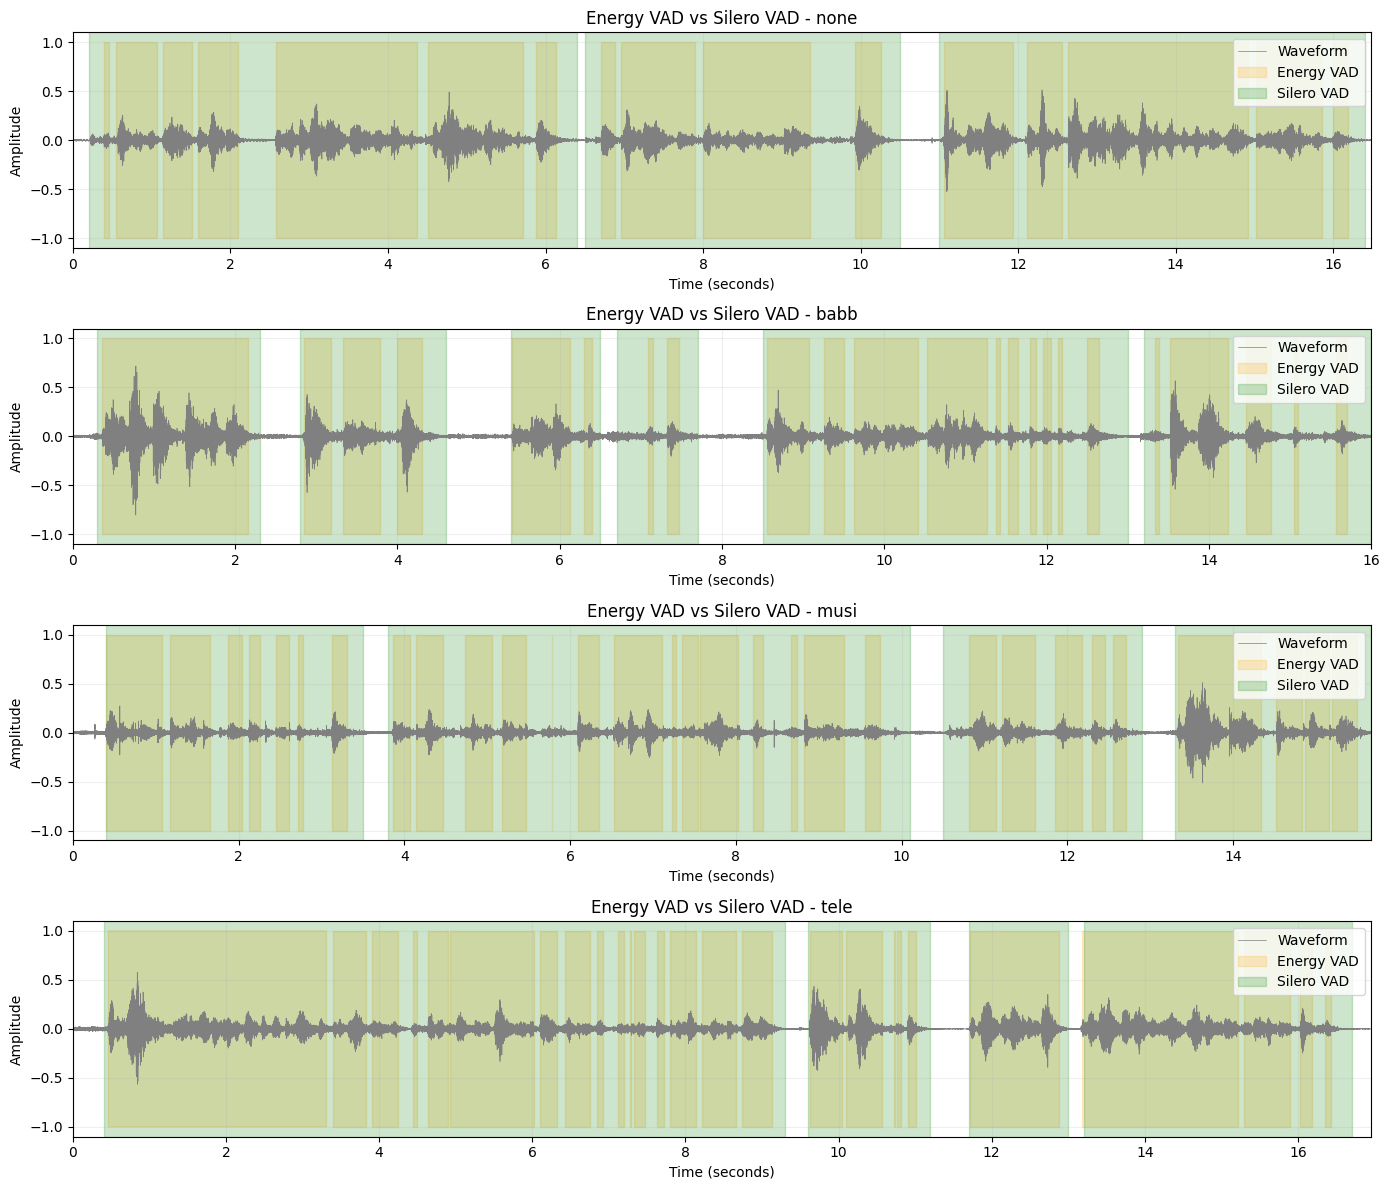


Energy VAD vs Silero VAD Comparison
Background  Duration_s  Energy_Speech_s  Silero_Speech_s  Frame_Agreement
      none      16.485            12.33            15.60           0.8015
      babb      16.005             8.23            13.20           0.6892
      musi      15.670             8.93            14.17           0.6658
      tele      16.960            12.53            15.30           0.8341

Comparison results saved successfully.


In [18]:
import numpy as np
import pandas as pd
import soundfile as sf
import torch
import matplotlib.pyplot as plt
from pathlib import Path
from silero_vad import get_speech_timestamps

backgrounds = ["none", "babb", "musi", "tele"]

comparison_results = []

fig, axes = plt.subplots(
    4, 1,
    figsize=(14, 12),
    sharey=True
)

for ax, background in zip(axes, backgrounds):

    sample = dataset_df[
        dataset_df["label"] == background
    ].iloc[0]

    signal, sr = sf.read(
        sample["path"],
        dtype="float32"
    )

    if signal.ndim == 2:
        signal = signal.mean(axis=1)

    if sr != 16000 or len(signal) == 0:
        raise ValueError("Invalid audio input")

    duration = len(signal) / sr

    frame_length = int(0.025 * sr)
    hop_length = int(0.010 * sr)

    frame_starts = np.arange(
        0,
        len(signal) - frame_length + 1,
        hop_length
    )

    frames = np.stack([
        signal[start:start + frame_length]
        for start in frame_starts
    ])

    rms = np.sqrt(
        np.mean(frames ** 2, axis=1)
    )

    log_energy = 20 * np.log10(
        rms + 1e-10
    )

    noise_floor = np.percentile(
        log_energy, 10
    )

    peak_level = np.percentile(
        log_energy, 95
    )

    threshold = noise_floor + 0.35 * (
        peak_level - noise_floor
    )

    energy_labels = (
        log_energy > threshold
    ).astype(float)

    smoothing_width = 11

    smoothed_energy = np.convolve(
        energy_labels,
        np.ones(smoothing_width) / smoothing_width,
        mode="same"
    )

    energy_speech = smoothed_energy > 0.5

    frame_times = (
        frame_starts + frame_length / 2
    ) / sr

    energy_duration = (
        np.sum(energy_speech)
        * hop_length / sr
    )

    silero_segments = get_speech_timestamps(
        torch.from_numpy(signal.copy()),
        vad_model,
        sampling_rate=sr,
        return_seconds=True
    )

    silero_duration = sum(
        segment["end"] - segment["start"]
        for segment in silero_segments
    )

    silero_frame_labels = np.zeros(
        len(frame_times),
        dtype=bool
    )

    for segment in silero_segments:
        silero_frame_labels |= (
            (frame_times >= segment["start"]) &
            (frame_times < segment["end"])
        )

    agreement = np.mean(
        energy_speech == silero_frame_labels
    )

    comparison_results.append({
        "Background": background,
        "Duration_s": round(duration, 3),
        "Energy_Speech_s": round(energy_duration, 3),
        "Silero_Speech_s": round(silero_duration, 3),
        "Frame_Agreement": round(agreement, 4)
    })

    time_axis = np.arange(
        len(signal)
    ) / sr

    ax.plot(
        time_axis,
        signal,
        color="gray",
        linewidth=0.5,
        label="Waveform"
    )

    ax.fill_between(
        frame_times,
        -1,
        1,
        where=energy_speech,
        color="orange",
        alpha=0.20,
        step="mid",
        label="Energy VAD"
    )

    for i, segment in enumerate(silero_segments):

        ax.axvspan(
            segment["start"],
            segment["end"],
            color="green",
            alpha=0.20,
            label="Silero VAD" if i == 0 else None
        )

    ax.set_title(
        f"Energy VAD vs Silero VAD - {background}"
    )

    ax.set_xlabel("Time (seconds)")
    ax.set_ylabel("Amplitude")
    ax.set_xlim(0, duration)
    ax.legend(loc="upper right")
    ax.grid(alpha=0.2)

plt.tight_layout()

output_path = Path("/content/MT9_figures")
output_path.mkdir(parents=True, exist_ok=True)

plt.savefig(
    output_path / "energy_vs_silero_vad.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

comparison_df = pd.DataFrame(
    comparison_results
)

print("\nEnergy VAD vs Silero VAD Comparison")
print(comparison_df.to_string(index=False))

comparison_df.to_csv(
    "/content/MT9_results/energy_vs_silero_vad.csv",
    index=False
)

print("\nComparison results saved successfully.")

## Low-Energy Acoustic Feature Extraction

I selected the lowest-energy 25% of frames per recording, computed the same 30 summary features, and retained the speaker-disjoint data partition.

In [19]:
import numpy as np
import pandas as pd
import librosa
from pathlib import Path

low_energy_rows = []
low_energy_errors = []

for index, row in enumerate(dataset_df.itertuples(index=False), start=1):

    try:
        signal, sr = librosa.load(
            row.path,
            sr=None,
            mono=True
        )

        if len(signal) == 0:
            raise ValueError("Empty audio signal")

        mfcc = librosa.feature.mfcc(
            y=signal,
            sr=sr,
            n_mfcc=13,
            n_fft=512,
            hop_length=160
        )

        rms = librosa.feature.rms(
            y=signal,
            frame_length=512,
            hop_length=160
        )

        zcr = librosa.feature.zero_crossing_rate(
            y=signal,
            frame_length=512,
            hop_length=160
        )

        n_frames = min(
            mfcc.shape[1],
            rms.shape[1],
            zcr.shape[1]
        )

        mfcc = mfcc[:, :n_frames]
        rms = rms[:, :n_frames]
        zcr = zcr[:, :n_frames]

        if n_frames == 0:
            raise ValueError("No valid analysis frames")

        selected_count = max(
            1,
            int(np.ceil(0.25 * n_frames))
        )

        selected_frames = np.argsort(
            rms[0]
        )[:selected_count]

        features = np.concatenate([
            np.mean(mfcc[:, selected_frames], axis=1),
            np.std(mfcc[:, selected_frames], axis=1),
            [
                np.mean(rms[:, selected_frames]),
                np.std(rms[:, selected_frames]),
                np.mean(zcr[:, selected_frames]),
                np.std(zcr[:, selected_frames])
            ]
        ])

        if len(features) != 30:
            raise ValueError("Unexpected feature count")

        if not np.all(np.isfinite(features)):
            raise ValueError("Invalid feature values")

        result = {
            "filename": row.filename,
            "label": row.label,
            "speaker": row.speaker
        }

        result.update(
            dict(zip(feature_names, features))
        )

        low_energy_rows.append(result)

    except Exception as e:
        low_energy_errors.append(
            (row.filename, str(e))
        )

    if index % 100 == 0:
        print(
            f"Processed {index}/{len(dataset_df)} recordings"
        )

low_energy_df = pd.DataFrame(low_energy_rows)

print("\nLow-Energy Feature Extraction Results")

print("Total recordings:", len(dataset_df))
print("Successfully processed:", len(low_energy_df))
print("Failed recordings:", len(low_energy_errors))
print("Number of features:", len(feature_names))

if not low_energy_df.empty:
    print(
        "Feature matrix shape:",
        low_energy_df[feature_names].shape
    )

if low_energy_errors:
    print("\nFirst errors:")
    for filename, error in low_energy_errors[:10]:
        print(filename, error)

if len(low_energy_df) == len(dataset_df) and not low_energy_errors:

    output_file = Path(
        "/content/MT9_low_energy_features.csv"
    )

    low_energy_df.to_csv(
        output_file,
        index=False
    )

    print("\nFeatures saved successfully.")
    print("Saved file:", output_file)

else:
    print("\nFeature extraction incomplete.")

Processed 100/908 recordings
Processed 200/908 recordings
Processed 300/908 recordings
Processed 400/908 recordings
Processed 500/908 recordings
Processed 600/908 recordings
Processed 700/908 recordings
Processed 800/908 recordings
Processed 900/908 recordings

Low-Energy Feature Extraction Results
Total recordings: 908
Successfully processed: 908
Failed recordings: 0
Number of features: 30
Feature matrix shape: (908, 30)

Features saved successfully.
Saved file: /content/MT9_low_energy_features.csv


## Background Classification: Low-Energy Features

I kept the SVM settings and train/test split unchanged to compare feature extraction strategies.

In [20]:
import numpy as np
import pandas as pd

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix
)

labels = ["none", "babb", "musi", "tele"]

assert low_energy_df["filename"].is_unique
assert set(low_energy_df["filename"]) == set(dataset_df["filename"])

low_energy_index = low_energy_df.set_index("filename")

train_low = low_energy_index.loc[train_df["filename"]]
test_low = low_energy_index.loc[test_df["filename"]]

X_train_low = train_low[feature_names].to_numpy()
X_test_low = test_low[feature_names].to_numpy()

y_train_low = train_low["label"].to_numpy()
y_test_low = test_low["label"].to_numpy()

assert len(X_train_low) == 666
assert len(X_test_low) == 242

assert np.isfinite(X_train_low).all()
assert np.isfinite(X_test_low).all()

assert np.array_equal(y_train_low, y_train)
assert np.array_equal(y_test_low, y_test)

assert set(train_low["speaker"]).isdisjoint(
    set(test_low["speaker"])
)

low_energy_svm = make_pipeline(
    StandardScaler(),
    SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale",
        random_state=42
    )
)

low_energy_svm.fit(X_train_low, y_train_low)

y_pred_low = low_energy_svm.predict(X_test_low)

low_accuracy = accuracy_score(
    y_test_low,
    y_pred_low
)

low_precision, low_recall, low_f1, _ = (
    precision_recall_fscore_support(
        y_test_low,
        y_pred_low,
        labels=labels,
        average="macro",
        zero_division=0
    )
)

low_cm = confusion_matrix(
    y_test_low,
    y_pred_low,
    labels=labels
)

comparison_df = pd.DataFrame({
    "Feature_Set": [
        "Whole Recording",
        "Low-Energy Frames"
    ],
    "Accuracy": [
        accuracy,
        low_accuracy
    ],
    "Macro_Precision": [
        precision,
        low_precision
    ],
    "Macro_Recall": [
        recall,
        low_recall
    ],
    "Macro_F1": [
        f1,
        low_f1
    ]
})

print("SVM Feature Comparison Results")
print(comparison_df.to_string(index=False))

print("\nAccuracy Difference (Percentage Points):")
print(
    round(
        (low_accuracy - accuracy) * 100,
        2
    )
)

print("\nLow-Energy Confusion Matrix:")
print(low_cm)

print("\nVerification:")
print("Training samples:", len(X_train_low))
print("Testing samples:", len(X_test_low))
print("Correct predictions:", np.trace(low_cm))
print("Confusion matrix total:", low_cm.sum())

assert low_cm.sum() == len(y_test_low)

print("\nComparison completed successfully.")

SVM Feature Comparison Results
      Feature_Set  Accuracy  Macro_Precision  Macro_Recall  Macro_F1
  Whole Recording  0.694215         0.693167      0.690501  0.690138
Low-Energy Frames  0.876033         0.873508      0.873325  0.873049

Accuracy Difference (Percentage Points):
18.18

Low-Energy Confusion Matrix:
[[55  0  0 10]
 [ 0 61  0  2]
 [ 1  0 54  4]
 [ 5  2  6 42]]

Verification:
Training samples: 666
Testing samples: 242
Correct predictions: 212
Confusion matrix total: 242

Comparison completed successfully.


## Paired Prediction Comparison

I used an exploratory exact McNemar test; recordings from the same speaker are not necessarily statistically independent.

In [21]:
import numpy as np
from scipy.stats import binomtest

assert len(y_test) == len(y_pred) == len(y_pred_low)
assert np.array_equal(y_test, y_test_low)

whole_correct = (y_pred == y_test)
low_correct = (y_pred_low == y_test)

both_correct = np.sum(whole_correct & low_correct)
both_wrong = np.sum(~whole_correct & ~low_correct)

whole_only = np.sum(whole_correct & ~low_correct)
low_only = np.sum(~whole_correct & low_correct)

discordant = whole_only + low_only

if discordant > 0:
    p_value = binomtest(
        k=int(min(whole_only, low_only)),
        n=int(discordant),
        p=0.5,
        alternative="two-sided"
    ).pvalue
else:
    p_value = 1.0

print("Paired SVM Comparison Results")

print("\nBoth models correct:", both_correct)
print("Both models wrong:", both_wrong)
print("Only Whole Recording correct:", whole_only)
print("Only Low-Energy Frames correct:", low_only)

print("\nTotal test samples:", len(y_test))
print("Discordant predictions:", discordant)

print("\nMcNemar Exact Test")
print("P-value:", round(p_value, 8))

print("\nVerification")

assert (
    both_correct
    + both_wrong
    + whole_only
    + low_only
) == len(y_test)

assert both_correct + whole_only == 168
assert both_correct + low_only == 212

print("All consistency checks passed.")

Paired SVM Comparison Results

Both models correct: 160
Both models wrong: 22
Only Whole Recording correct: 8
Only Low-Energy Frames correct: 52

Total test samples: 242
Discordant predictions: 60

McNemar Exact Test
P-value: 1e-08

Verification
All consistency checks passed.


## Speaker-Grouped Five-Fold Cross-Validation

I evaluated both feature sets in five speaker-grouped folds of the training partition only.

In [22]:
import numpy as np
import pandas as pd

from sklearn.model_selection import GroupKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

cv = GroupKFold(n_splits=5)

train_whole_cv = feature_index.loc[train_df["filename"]]
train_low_cv = low_energy_index.loc[train_df["filename"]]

X_whole_cv = train_whole_cv[feature_names].to_numpy()
X_low_cv = train_low_cv[feature_names].to_numpy()

y_cv = train_whole_cv["label"].to_numpy()
groups_cv = train_whole_cv["speaker"].to_numpy()

assert np.array_equal(
    y_cv,
    train_low_cv["label"].to_numpy()
)

assert np.array_equal(
    groups_cv,
    train_low_cv["speaker"].to_numpy()
)

assert len(y_cv) == 666
assert np.isfinite(X_whole_cv).all()
assert np.isfinite(X_low_cv).all()

def build_svm():
    return make_pipeline(
        StandardScaler(),
        SVC(
            kernel="rbf",
            C=1.0,
            gamma="scale",
            random_state=42
        )
    )

splits = list(
    cv.split(X_whole_cv, y_cv, groups_cv)
)

for tr, te in splits:
    assert set(groups_cv[tr]).isdisjoint(
        set(groups_cv[te])
    )

scoring = {
    "Accuracy": "accuracy",
    "Macro_F1": "f1_macro"
}

whole_scores = cross_validate(
    build_svm(),
    X_whole_cv,
    y_cv,
    cv=splits,
    scoring=scoring,
    n_jobs=1
)

low_scores = cross_validate(
    build_svm(),
    X_low_cv,
    y_cv,
    cv=splits,
    scoring=scoring,
    n_jobs=1
)

cv_results = pd.DataFrame({
    "Fold": np.arange(1, 6),
    "Whole_Accuracy": whole_scores["test_Accuracy"],
    "Low_Energy_Accuracy": low_scores["test_Accuracy"],
    "Whole_Macro_F1": whole_scores["test_Macro_F1"],
    "Low_Energy_Macro_F1": low_scores["test_Macro_F1"]
})

cv_results["Accuracy_Improvement_PP"] = (
    cv_results["Low_Energy_Accuracy"]
    - cv_results["Whole_Accuracy"]
) * 100

print("Speaker-Grouped 5-Fold Cross-Validation Results\n")

print(
    cv_results.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

print("\nMean Results:")

for column in cv_results.columns[1:]:
    print(
        column,
        ":",
        round(cv_results[column].mean(), 4)
    )

output_file = (
    "/content/MT9_results/"
    "speaker_grouped_cv_comparison.csv"
)

cv_results.to_csv(output_file, index=False)

print("\nResults saved:", output_file)

Speaker-Grouped 5-Fold Cross-Validation Results

 Fold  Whole_Accuracy  Low_Energy_Accuracy  Whole_Macro_F1  Low_Energy_Macro_F1  Accuracy_Improvement_PP
    1          0.7463               0.9104          0.7537               0.9137                  16.4179
    2          0.7218               0.9323          0.7222               0.9325                  21.0526
    3          0.6391               0.8120          0.6397               0.8119                  17.2932
    4          0.6692               0.8271          0.6536               0.8216                  15.7895
    5          0.7594               0.9098          0.7440               0.9036                  15.0376

Mean Results:
Whole_Accuracy : 0.7071
Low_Energy_Accuracy : 0.8783
Whole_Macro_F1 : 0.7026
Low_Energy_Macro_F1 : 0.8766
Accuracy_Improvement_PP : 17.1182

Results saved: /content/MT9_results/speaker_grouped_cv_comparison.csv


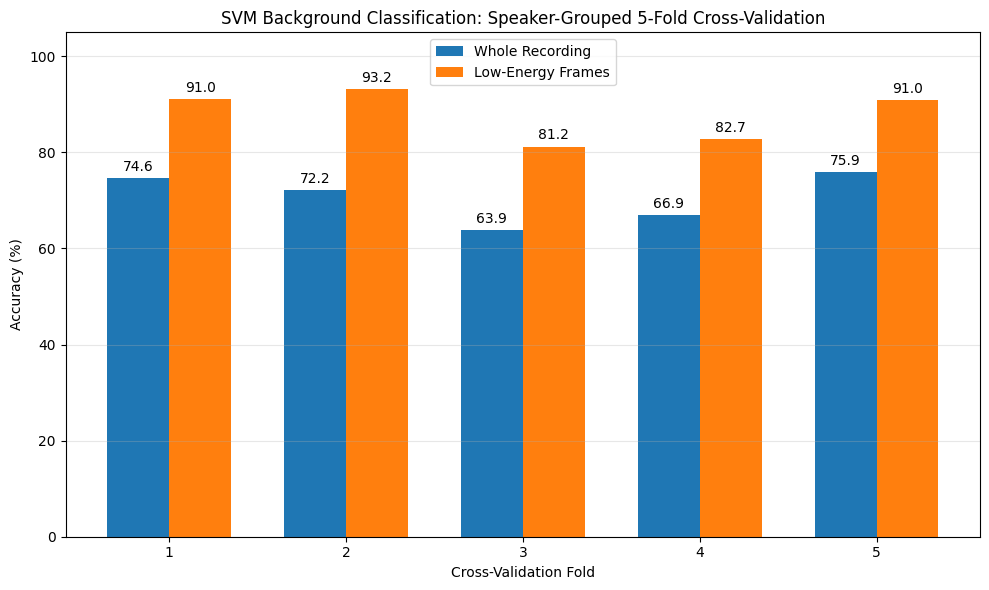

Figure saved: /content/MT9_figures/svm_grouped_cv_comparison.png
Figure exists: True

Mean Whole Accuracy: 70.71
Mean Low-Energy Accuracy: 87.83


In [23]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

figures_path = Path("/content/MT9_figures")
figures_path.mkdir(parents=True, exist_ok=True)

folds = cv_results["Fold"].to_numpy()

whole_acc = cv_results["Whole_Accuracy"].to_numpy() * 100
low_acc = cv_results["Low_Energy_Accuracy"].to_numpy() * 100

x = np.arange(len(folds))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))

bars1 = ax.bar(
    x - width / 2,
    whole_acc,
    width,
    label="Whole Recording"
)

bars2 = ax.bar(
    x + width / 2,
    low_acc,
    width,
    label="Low-Energy Frames"
)

ax.set_xlabel("Cross-Validation Fold")
ax.set_ylabel("Accuracy (%)")
ax.set_title(
    "SVM Background Classification: "
    "Speaker-Grouped 5-Fold Cross-Validation"
)

ax.set_xticks(x)
ax.set_xticklabels(folds)

ax.set_ylim(0, 105)
ax.legend()
ax.grid(axis="y", alpha=0.3)

ax.bar_label(bars1, fmt="%.1f", padding=3)
ax.bar_label(bars2, fmt="%.1f", padding=3)

plt.tight_layout()

output_file = figures_path / "svm_grouped_cv_comparison.png"

plt.savefig(
    output_file,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved:", output_file)
print("Figure exists:", output_file.exists())

print("\nMean Whole Accuracy:", round(whole_acc.mean(), 2))
print("Mean Low-Energy Accuracy:", round(low_acc.mean(), 2))

## Extended VAD Agreement Study: Forty Recordings

I selected ten recordings from each background condition and compared the two VAD predictions without reference speech annotations.

In [24]:
import numpy as np
import pandas as pd
import soundfile as sf
import torch
from pathlib import Path
from silero_vad import get_speech_timestamps

backgrounds = ["none", "babb", "musi", "tele"]

sample_size = 10
random_state = 42

selected_df = pd.concat([
    dataset_df[dataset_df["label"] == bg].sample(
        n=sample_size,
        random_state=random_state
    )
    for bg in backgrounds
], ignore_index=True)

results = []

for index, row in enumerate(
    selected_df.itertuples(index=False),
    start=1
):

    signal, sr = sf.read(
        row.path,
        dtype="float32"
    )

    if signal.ndim == 2:
        signal = signal.mean(axis=1)

    if sr != 16000 or len(signal) < 400:
        raise ValueError(
            f"Invalid audio: {row.filename}"
        )

    duration = len(signal) / sr

    frame_length = 400
    hop_length = 160

    frame_starts = np.arange(
        0,
        len(signal) - frame_length + 1,
        hop_length
    )

    frames = np.stack([
        signal[start:start + frame_length]
        for start in frame_starts
    ])

    rms = np.sqrt(
        np.mean(frames.astype(np.float64) ** 2, axis=1)
    )

    log_energy = 20 * np.log10(rms + 1e-10)

    noise_floor = np.percentile(log_energy, 10)
    peak_level = np.percentile(log_energy, 95)

    threshold = noise_floor + 0.35 * (
        peak_level - noise_floor
    )

    energy_labels = (
        log_energy > threshold
    ).astype(float)

    smoothed = np.convolve(
        energy_labels,
        np.ones(11) / 11,
        mode="same"
    )

    energy_speech = smoothed > 0.5

    frame_times = (
        frame_starts + frame_length / 2
    ) / sr

    silero_segments = get_speech_timestamps(
        torch.from_numpy(signal.copy()),
        vad_model,
        sampling_rate=sr,
        return_seconds=True
    )

    silero_speech = np.zeros(
        len(frame_times),
        dtype=bool
    )

    for segment in silero_segments:
        silero_speech |= (
            (frame_times >= segment["start"]) &
            (frame_times < segment["end"])
        )

    agreement = np.mean(
        energy_speech == silero_speech
    )

    energy_ratio = np.mean(energy_speech)
    silero_ratio = np.mean(silero_speech)

    results.append({
        "Filename": row.filename,
        "Background": row.label,
        "Duration_s": duration,
        "Energy_Speech_Ratio": energy_ratio,
        "Silero_Speech_Ratio": silero_ratio,
        "Frame_Agreement": agreement,
        "Energy_Only_Ratio": np.mean(
            energy_speech & ~silero_speech
        ),
        "Silero_Only_Ratio": np.mean(
            ~energy_speech & silero_speech
        )
    })

    if index % 10 == 0:
        print(
            f"Processed {index}/{len(selected_df)} recordings"
        )

vad_multi_df = pd.DataFrame(results)

summary_df = vad_multi_df.groupby(
    "Background"
).agg(
    Recordings=("Filename", "count"),
    Mean_Duration_s=("Duration_s", "mean"),
    Mean_Energy_Speech_Ratio=(
        "Energy_Speech_Ratio", "mean"
    ),
    Mean_Silero_Speech_Ratio=(
        "Silero_Speech_Ratio", "mean"
    ),
    Mean_Frame_Agreement=(
        "Frame_Agreement", "mean"
    ),
    Std_Frame_Agreement=(
        "Frame_Agreement", "std"
    ),
    Mean_Energy_Only_Ratio=(
        "Energy_Only_Ratio", "mean"
    ),
    Mean_Silero_Only_Ratio=(
        "Silero_Only_Ratio", "mean"
    )
).reset_index()

assert len(vad_multi_df) == 40
assert vad_multi_df["Filename"].is_unique
assert vad_multi_df["Frame_Agreement"].between(0, 1).all()

assert np.allclose(
    vad_multi_df["Frame_Agreement"]
    + vad_multi_df["Energy_Only_Ratio"]
    + vad_multi_df["Silero_Only_Ratio"],
    1.0
)

results_path = Path("/content/MT9_results")
results_path.mkdir(parents=True, exist_ok=True)

vad_multi_df.to_csv(
    results_path / "vad_40_recordings.csv",
    index=False
)

summary_df.to_csv(
    results_path / "vad_40_recordings_summary.csv",
    index=False
)

print("\nVAD Multi-Recording Evaluation Results")

print("\nTotal evaluated recordings:", len(vad_multi_df))

print("\nBackground Summary:")
print(
    summary_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

print("\nOverall Mean Frame Agreement:",
      round(vad_multi_df["Frame_Agreement"].mean(), 4))

print("\nAll consistency checks passed.")
print("Results saved successfully.")

Processed 10/40 recordings
Processed 20/40 recordings
Processed 30/40 recordings
Processed 40/40 recordings

VAD Multi-Recording Evaluation Results

Total evaluated recordings: 40

Background Summary:
Background  Recordings  Mean_Duration_s  Mean_Energy_Speech_Ratio  Mean_Silero_Speech_Ratio  Mean_Frame_Agreement  Std_Frame_Agreement  Mean_Energy_Only_Ratio  Mean_Silero_Only_Ratio
      babb          10          14.9530                    0.6409                    0.8916                0.7490               0.0959                  0.0002                  0.2508
      musi          10          16.0180                    0.6375                    0.8553                0.7644               0.1391                  0.0088                  0.2267
      none          10          15.5415                    0.7357                    0.8348                0.8884               0.0509                  0.0062                  0.1054
      tele          10          15.8130                    0.7310  

## Extended VAD Visualization

I visualized mean frame agreement and standard deviation across the selected recordings.

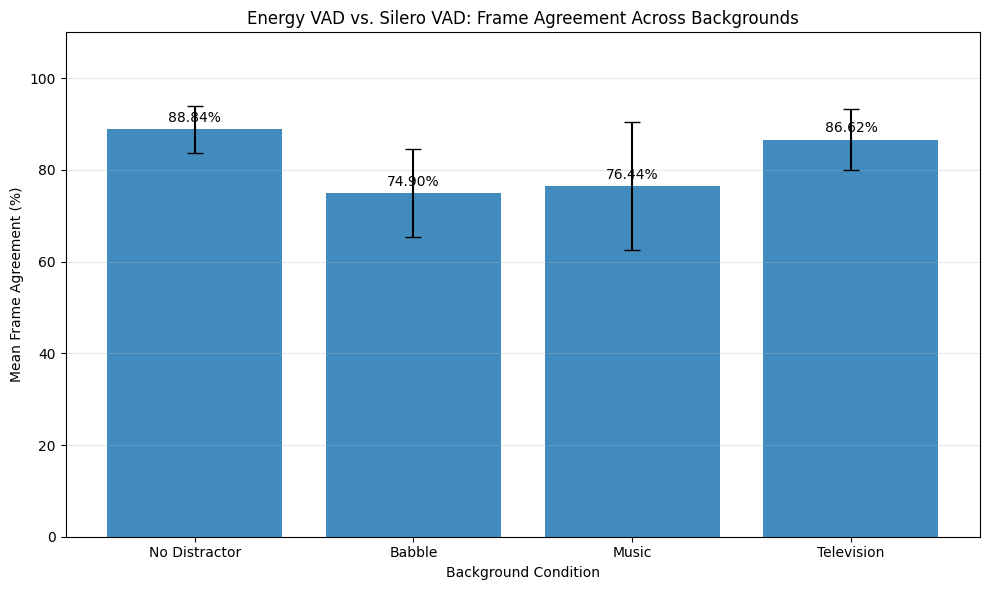

Figure saved: /content/MT9_figures/vad_40_recordings_comparison.png
Figure exists: True
Overall Mean Agreement: 81.7 %


In [25]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

background_order = ["none", "babb", "musi", "tele"]

plot_df = summary_df.set_index("Background").loc[background_order]

means = plot_df["Mean_Frame_Agreement"].to_numpy() * 100
stds = plot_df["Std_Frame_Agreement"].to_numpy() * 100

display_names = [
    "No Distractor",
    "Babble",
    "Music",
    "Television"
]

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    display_names,
    means,
    yerr=stds,
    capsize=6,
    alpha=0.85
)

for bar, value in zip(bars, means):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + 1,
        f"{value:.2f}%",
        ha="center",
        va="bottom",
        fontsize=10
    )

ax.set_title(
    "Energy VAD vs. Silero VAD: Frame Agreement Across Backgrounds"
)

ax.set_xlabel("Background Condition")
ax.set_ylabel("Mean Frame Agreement (%)")

ax.set_ylim(0, 110)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

figures_path = Path("/content/MT9_figures")
figures_path.mkdir(parents=True, exist_ok=True)

output_file = figures_path / "vad_40_recordings_comparison.png"

plt.savefig(
    output_file,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved:", output_file)
print("Figure exists:", output_file.exists())

print("Overall Mean Agreement:",
      round(vad_multi_df["Frame_Agreement"].mean() * 100, 2),
      "%")

## Discussion

In this mini-task, I used the VOiCES-subset dataset to investigate background sound classification and voice activity detection under different acoustic conditions.

### 1. Background Classification

I worked with 908 valid audio recordings containing four background conditions: no distractor, babble, music, and television.

I extracted 30 acoustic features from each recording, including MFCC statistics, RMS energy, and zero-crossing rate features.

I divided the dataset into 666 training recordings and 242 testing recordings using a speaker-independent split. This ensured that no speaker appeared in both sets.

First, I trained an SVM classifier using features extracted from the entire recordings. The model achieved 69.42% test accuracy and a macro F1-score of 0.6901.

I examined the confusion matrix and observed that babble was the easiest background to classify, while television was the most difficult.

### 2. Whole-Recording vs. Low-Energy Features

I then investigated whether selecting low-energy frames could improve background classification.

For each recording, I selected the 25% of analysis frames with the lowest RMS energy and extracted the same 30 acoustic features.

I used the same SVM configuration and the same training and testing split to make the comparison consistent.

I improved test accuracy from 69.42% to 87.60% using the low-energy approach, an increase of 18.18 percentage points.

I also increased the macro F1-score from 0.6901 to 0.8730.

I increased the number of correctly classified test recordings from 168 to 212 out of 242.

I interpret this as evidence that lower-energy regions carry useful information for distinguishing the background conditions in these recordings. I think reduced foreground-speech dominance in some frames is one possible explanation.

However, I did not verify that the selected low-energy frames were silent or that they coincided with true speech pauses.

### 3. Statistical Comparison

I compared the predictions of the two SVM models using McNemar's exact test.

Both models correctly classified 160 recordings and incorrectly classified 22 recordings.

The whole-recording model alone correctly classified 8 recordings, while the low-energy model alone correctly classified 52 recordings.

The exact test produced a p-value of approximately 5.21 × 10⁻⁹.

I observed a substantial difference between the paired predictions in the evaluated test set.

However, this statistical result should be interpreted cautiously because recordings from the same speaker may be correlated. The test set was also used during the exploratory comparison of feature extraction methods.

Therefore, I consider this analysis supporting evidence rather than a definitive confirmatory statistical test.

### 4. Speaker-Grouped Cross-Validation

To examine whether the improvement was consistent across different speakers, I performed five-fold cross-validation on the training recordings only, grouping the folds by speaker identity.

The whole-recording SVM achieved a mean accuracy of 70.71% and a mean macro F1-score of 0.7026.

The low-energy SVM achieved a mean accuracy of 87.83% and a mean macro F1-score of 0.8766.

The average accuracy improvement was approximately 17.12 percentage points.

I observed that the low-energy approach performed better in all five folds.

I took these consistent fold-wise improvements as additional evidence that the result was not limited to a single train/test partition.

### 5. Voice Activity Detection

For the second part of the mini-task, I implemented two voice activity detection methods:

1. Classical energy-based VAD.
2. Pretrained Silero VAD.

I first applied both methods to four recordings representing the four background conditions and visualized their detected speech regions.

I observed that Silero detected longer speech intervals than the energy-based method in all four examples.

I observed more fragmented detected-speech intervals from the energy-based method in the illustrated babble and music recordings.

I then extended the comparison to 40 recordings, selecting 10 recordings from each background condition.

The mean frame agreement between the two methods was:

| Background    | Mean Frame Agreement |
| ------------- | -------------------: |
| No Distractor |               88.84% |
| Babble        |               74.90% |
| Music         |               76.44% |
| Television    |               86.62% |
| Overall       |               81.70% |

I observed the highest agreement in the recordings without a distractor and the lowest agreement in the babble condition.

Across the 40 recordings, the mean speech detection ratios were approximately 68.63% for Energy VAD and 85.85% for Silero VAD.

I found that Silero classified a larger proportion of the analyzed frames as speech.

However, a higher speech detection ratio does not necessarily mean better accuracy.

I treated these values as agreement between the two methods, not as agreement with independently verified speech labels.

### 6. Limitations

I recognize several limitations in these experiments.

First, I classified the background category of an entire recording; I did not estimate the start and end times of individual background events.

Second, I selected low-energy frames based on relative RMS energy, not on verified speech or silence labels.

Third, I conducted the classification experiments on VOiCES-subset only. I cannot assume the same numerical results for other datasets or acoustic conditions.

Fourth, I compared the VAD methods on 40 selected recordings rather than the entire dataset. I did not control the speaker, utterance, microphone, and room conditions sufficiently to isolate the effect of background type alone.

Finally, I did not have independently annotated speech intervals for the VAD experiment. I therefore compared the predictions of the two methods without reporting ground-truth-based accuracy, precision, recall, or F1-scores.

## Conclusion

In this mini-task, I completed two main experiments using the VOiCES-subset dataset.

For background classification, I trained an SVM classifier using acoustic features extracted from speech recordings under four background conditions.

The initial model achieved 69.42% test accuracy.

I then introduced a low-energy feature extraction approach, which improved test accuracy to 87.60%.

Speaker-grouped five-fold cross-validation supported this observation, with mean accuracy increasing from 70.71% to 87.83%.

For voice activity detection, I implemented and compared classical Energy VAD and pretrained Silero VAD.

The extended comparison across 40 recordings produced an overall mean frame agreement of 81.70%.

I found that feature selection influenced my background classification results and that the two VAD methods produced different predicted speech intervals under the tested acoustic conditions.

Overall, this mini-task helped me understand the relationship between acoustic features, background sound classification, and speech activity detection in noisy recordings.


## References

1. C. Richey et al., “Voices Obscured in Complex Environmental Settings (VOiCES) corpus,” *Interspeech*, 2018. https://www.isca-archive.org/interspeech_2018/richey18_interspeech.pdf
2. Lab41, “VOiCES-subset,” GitHub repository. https://github.com/Lab41/VOiCES-subset
3. Silero Team, “Silero VAD,” GitHub repository. https://github.com/snakers4/silero-vad
4. Maël Fabien, “Voice Activity Detection Application,” tutorial. https://maelfabien.github.io/project/Speech_proj/#high-level-overview